# ECG/HRV Anxiety-Level Estimation

This notebook covers exploratory data analysis (EDA), subject-aware model training, and evaluation on a labeled test file. It reuses the project functions from `src/data.py`, `src/train.py`, and `src/evaluate.py` instead of duplicating their core logic.

The model uses engineered ECG/HRV features, not raw ECG waveforms.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = Path('..').resolve()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from data import GROUP, TARGET, feature_columns, load_datasets
from train import LABEL_ORDER, build_models

DATA_DIR = Path('/Users/nishantnikhil/Downloads')
OUTPUT_DIR = PROJECT_ROOT / 'artifacts' / 'notebook-model'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_FILES = [
    DATA_DIR / 'ecg_hrv_dataset.csv',
    DATA_DIR / 'ecg_hrv_dataset_2.csv',
    DATA_DIR / 'ecg_hrv_dataset_synthetic_10k.csv',
]
TEST_FILE = DATA_DIR / 'ecg_hrv_prediction_labeled.csv'
SEED = 42
pd.set_option('display.max_columns', 30)

## 1. Load and validate the training data

In [2]:
data = load_datasets(TRAIN_FILES)
features = feature_columns(data)
print(f'Rows: {len(data):,}')
print(f'Subjects: {data[GROUP].nunique():,}')
print(f'Features: {len(features)}')
display(data.head())
display(data[TARGET].value_counts().rename('count').to_frame())
display(data[features].isna().sum().sort_values(ascending=False).head(10).rename('missing_values').to_frame())

Removed 100 duplicate subject/window rows.
Rows: 29,900
Subjects: 299
Features: 21


,subject_id,window_id,age,mean_hr_bpm,mean_rr_ms,sdnn_ms,rmssd_ms,pnn50_pct,hr_std_bpm,lf_power_ms2,hf_power_ms2,lf_hf_ratio,lf_nu,hf_nu,total_power_ms2,sd1_ms,sd2_ms,sd1_sd2_ratio,sample_entropy,ecg_resp_rate_bpm,r_peak_amp_mv,qrs_duration_ms,signal_quality_index,anxiety_level
0,S032,4,44,57.7,1040.3,45.3,39.8,14.05,2.51,901.3,713.9,1.262,55.8,44.2,1900.3,28.69,57.22,0.501,1.599,13.2,1.385,83.0,0.923,Low
1,S064,53,52,84.8,708.0,32.7,25.4,4.30,3.92,319.2,640.3,0.499,33.3,66.7,1128.8,17.57,42.83,0.410,1.501,13.1,1.078,86.3,0.734,Low
2,S087,89,43,94.2,636.8,29.0,19.6,3.60,4.30,506.2,192.8,2.626,72.4,27.6,822.3,13.87,38.65,0.359,0.916,19.6,1.070,102.3,0.860,High
3,S059,57,58,71.5,839.7,54.2,34.8,12.57,4.61,1344.9,1337.7,1.005,50.1,49.9,3155.9,24.71,72.59,0.340,1.599,14.8,1.157,97.4,0.965,Low
4,S061,11,34,90.6,662.2,17.2,11.1,1.29,2.35,209.2,32.0,6.534,86.7,13.3,283.8,7.69,23.08,0.333,0.851,22.0,0.650,95.8,0.958,High


,count
anxiety_level,
Low,13189
Medium,9636
High,7075


,missing_values
lf_nu,908
lf_hf_ratio,908
hf_nu,908
sample_entropy,482
lf_power_ms2,478
hf_power_ms2,435
sd1_ms,0
qrs_duration_ms,0
r_peak_amp_mv,0
ecg_resp_rate_bpm,0


## 2. Exploratory data analysis

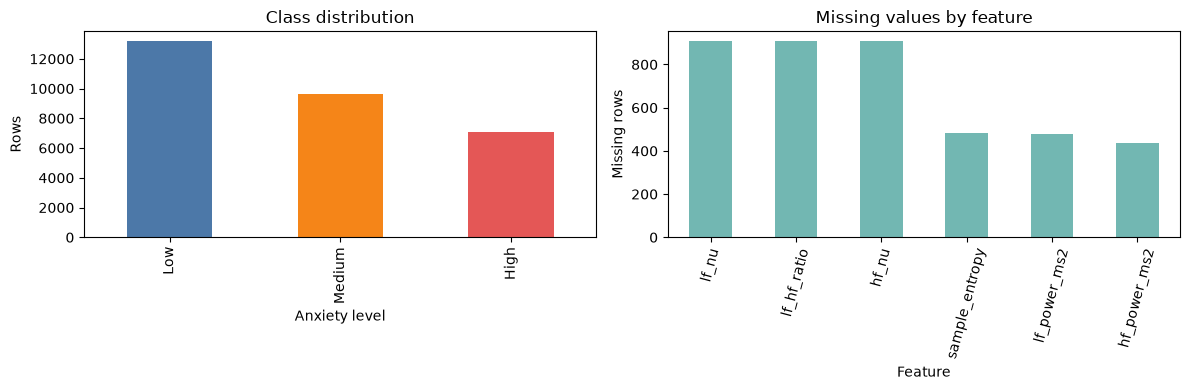

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data[TARGET].value_counts().reindex(LABEL_ORDER).plot.bar(ax=axes[0], color=['#4c78a8', '#f58518', '#e45756'])
axes[0].set_title('Class distribution')
axes[0].set_xlabel('Anxiety level')
axes[0].set_ylabel('Rows')

missing = data[features].isna().sum().sort_values(ascending=False)
missing[missing > 0].plot.bar(ax=axes[1], color='#72b7b2')
axes[1].set_title('Missing values by feature')
axes[1].set_xlabel('Feature')
axes[1].set_ylabel('Missing rows')
axes[1].tick_params(axis='x', rotation=75)
plt.tight_layout()

,mean_hr_bpm,rmssd_ms,sdnn_ms,lf_hf_ratio
anxiety_level,,,,
Low,70.52,49.60,64.52,1.32
Medium,82.04,35.92,49.43,2.38
High,94.07,22.31,33.20,4.01


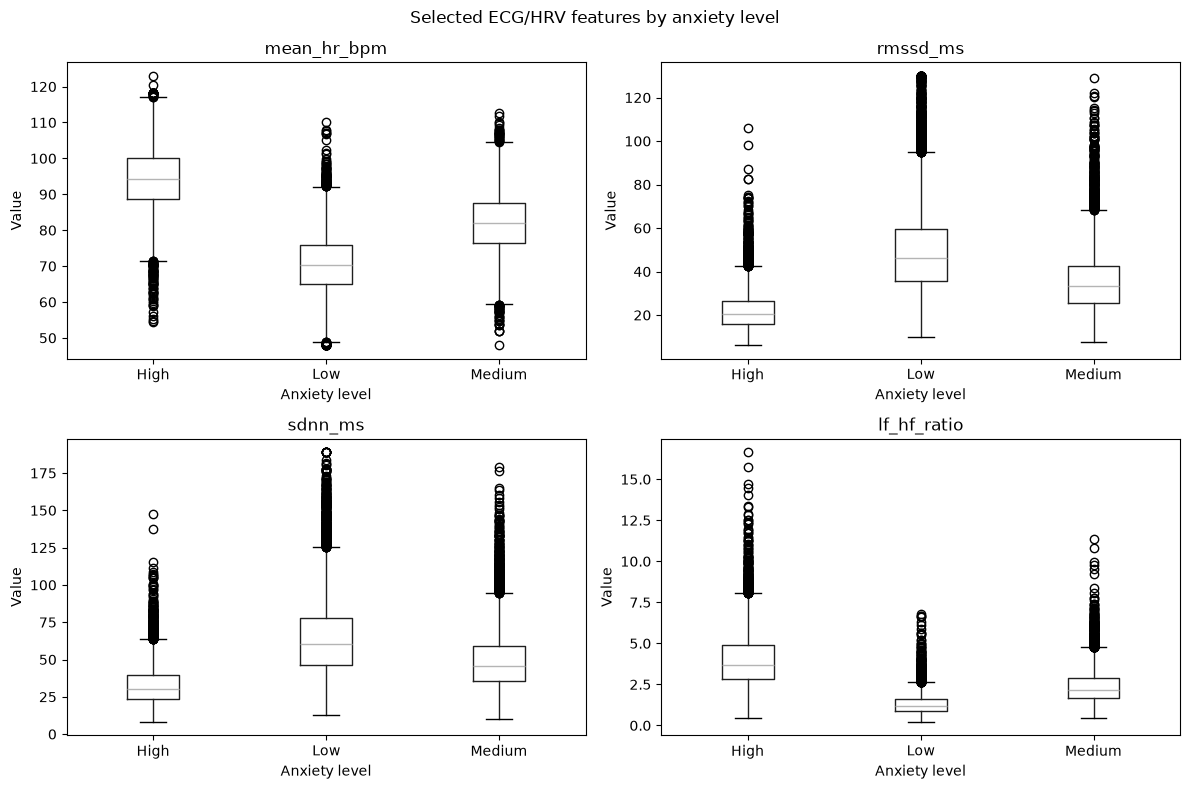

In [4]:
eda_features = ['mean_hr_bpm', 'rmssd_ms', 'sdnn_ms', 'lf_hf_ratio']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.flat, eda_features):
    data.boxplot(column=column, by=TARGET, ax=ax, grid=False)
    ax.set_title(column)
    ax.set_xlabel('Anxiety level')
    ax.set_ylabel('Value')
plt.suptitle('Selected ECG/HRV features by anxiety level')
plt.tight_layout()
display(data.groupby(TARGET)[eda_features].mean().reindex(LABEL_ORDER).round(2))

## 3. Subject-aware training

Windows from the same subject must not appear in both train and test. The grouped split below prevents subject leakage.

In [5]:
X = data[features]
y = data[TARGET]
groups = data[GROUP]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, holdout_idx = next(splitter.split(X, y, groups))
X_train, X_holdout = X.iloc[train_idx], X.iloc[holdout_idx]
y_train, y_holdout = y.iloc[train_idx], y.iloc[holdout_idx]
groups_train = groups.iloc[train_idx]
print(f'Train rows: {len(train_idx):,}; holdout rows: {len(holdout_idx):,}')
print(f'Train subjects: {groups.iloc[train_idx].nunique()}; holdout subjects: {groups.iloc[holdout_idx].nunique()}')
print('Subject overlap:', len(set(groups.iloc[train_idx]) & set(groups.iloc[holdout_idx])))

Train rows: 23,900; holdout rows: 6,000
Train subjects: 239; holdout subjects: 60
Subject overlap: 0


In [6]:
models = build_models(SEED)
cv = GroupKFold(n_splits=min(5, groups_train.nunique()))
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, groups=groups_train, cv=cv, scoring='f1_macro')
    cv_results[name] = scores
    print(f'{name}: folds={scores.round(4)}, mean_macro_f1={scores.mean():.4f}')

best_name = max(cv_results, key=lambda name: cv_results[name].mean())
best_model = models[best_name].fit(X_train, y_train)
holdout_predictions = best_model.predict(X_holdout)
print('Selected model:', best_name)
print(f"Holdout macro-F1: {f1_score(y_holdout, holdout_predictions, labels=LABEL_ORDER, average='macro'):.4f}")

logistic_regression: folds=[0.8961 0.8851 0.885  0.9015 0.8951], mean_macro_f1=0.8926
random_forest: folds=[0.8889 0.8815 0.8804 0.8909 0.8918], mean_macro_f1=0.8867
Selected model: logistic_regression
Holdout macro-F1: 0.8841


In [7]:
joblib.dump(best_model, OUTPUT_DIR / 'model.joblib')
metadata = {
    'target': TARGET,
    'group_column': GROUP,
    'feature_columns': features,
    'labels': LABEL_ORDER,
    'selected_model': best_name,
}
(OUTPUT_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Saved model to', OUTPUT_DIR / 'model.joblib')

Saved model to /Users/nishantnikhil/Downloads/real anxiety det/artifacts/notebook-model/model.joblib


## 4. Evaluate on the labeled external test dataset

In [8]:
test = pd.read_csv(TEST_FILE)
test_actual = test[TARGET].astype('string').str.strip().str.title()
test_predicted = best_model.predict(test[features])

print(f'Records: {len(test):,}')
print(f'Accuracy: {accuracy_score(test_actual, test_predicted):.4f}')
print(f'Balanced accuracy: {balanced_accuracy_score(test_actual, test_predicted):.4f}')
print(f"Macro-F1: {f1_score(test_actual, test_predicted, labels=LABEL_ORDER, average='macro'):.4f}")
print(classification_report(test_actual, test_predicted, labels=LABEL_ORDER, zero_division=0))

Records: 2,000
Accuracy: 0.8825
Balanced accuracy: 0.8855
Macro-F1: 0.8769
              precision    recall  f1-score   support

         Low       0.94      0.92      0.93       862
      Medium       0.85      0.82      0.84       732
        High       0.81      0.92      0.86       406

    accuracy                           0.88      2000
   macro avg       0.87      0.89      0.88      2000
weighted avg       0.88      0.88      0.88      2000



Saved evaluation predictions to /Users/nishantnikhil/Downloads/real anxiety det/artifacts/notebook-model/labeled_test_predictions.csv


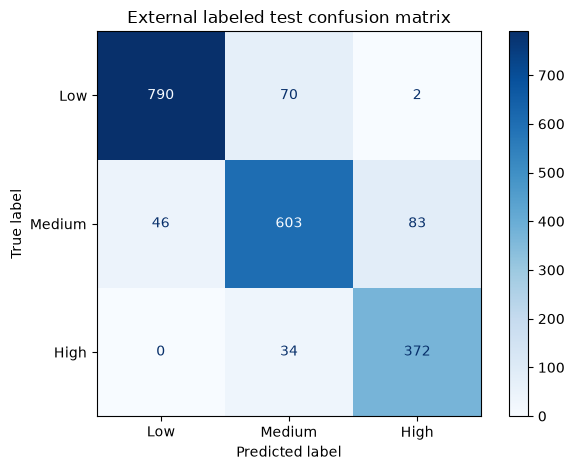

In [9]:
matrix = confusion_matrix(test_actual, test_predicted, labels=LABEL_ORDER)
ConfusionMatrixDisplay(matrix, display_labels=LABEL_ORDER).plot(cmap='Blues', values_format='d')
plt.title('External labeled test confusion matrix')
plt.tight_layout()

test_results = test.copy()
test_results['predicted_anxiety_level'] = test_predicted
test_results.to_csv(OUTPUT_DIR / 'labeled_test_predictions.csv', index=False)
print('Saved evaluation predictions to', OUTPUT_DIR / 'labeled_test_predictions.csv')